# 02 — Cleaning & preprocessing: SNOTEL station data

**Canvas project group:** 37 · **Members:** Nat Toms, Owen Cruz-Abrams, Martha le Huray

**Purpose.** This notebook turns the raw SNOTEL downloads into one clean daily table, covering all 20 candidate stations.
Later choices of resort and station then only need to select rows. It works through every item in MS2's
*Issues to check during cleaning and preprocessing*:
missing data (§3), unusual values (§4–5), class imbalance (§8), feature scale (§9) and information leakage (§10).
Every step states **what / why / decision**, prints how many rows it affected, and appends a row to the cleaning log.

**Inputs** (read-only, offline): the 20 raw SNOTEL JSON files under `data/raw/snotel/`, downloaded in notebook 01 §2.3,
plus the station metadata file. §1 checks their SHA-256 against `data/raw/MANIFEST.csv`. With `SNOWPREDICT_OFFLINE=1`,
`lineage.fetch` raises an error instead of downloading, so this notebook cannot use any data that isn't logged.

**Outputs**
- `data/processed/snotel_clean.parquet`: one row per station-day, SI units, with per-variable provenance columns.
- `data/processed/cleaning_log.csv`: every rule, how many rows it affected, the action taken, and why.
- `data/processed/snotel_clean_columns.csv`: data dictionary.

Reusable logic lives in `src/clean.py` and is unit-tested in `tests/test_clean.py`.

In [1]:
import os, sys, hashlib
from pathlib import Path
os.environ["SNOWPREDICT_OFFLINE"] = "1"          # never download from this notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import lineage, parse, sites, clean

pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 100)
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 14, "axes.labelsize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11})
OUT = ROOT / "data" / "processed"; OUT.mkdir(parents=True, exist_ok=True)
ELEMENTS = sites.SNOTEL_ELEMENTS          # SNWD, WTEQ, TAVG, TMAX, TMIN, PREC, PRCP
CAND = list(sites.CANDIDATE_STATIONS)

LOG = []
def log(step, rule, column, n, action, reason, scope="all candidate stations"):
    LOG.append(dict(step=step, rule=rule, column=column, scope=scope, n_affected=int(n), action=action, reason=reason))
    print(f"[{step}] {rule} | {column}: {int(n):,} rows -> {action}")

## 1. Load raw data and verify lineage
We use exactly the same request parameters as notebook 01 §2.3, so `lineage.snotel` maps them to the same cached files.
Each file's SHA-256 is then re-computed and compared with the manifest.

In [2]:
def snotel_params(trip):
    return {"stationTriplets": trip, "elements": ",".join(ELEMENTS), "duration": "DAILY",
            "beginDate": sites.SNOTEL_PERIOD[0], "endDate": sites.SNOTEL_PERIOD[1], "periodRef": "END",
            "returnFlags": "true", "returnOriginalValues": "true", "returnSuspectData": "true"}

sn = pd.concat([parse.snotel_to_long(lineage.snotel("data", snotel_params(t), name=f"daily_{t.replace(':', '_')}"))
                for t in CAND], ignore_index=True)
meta_raw = lineage.snotel("stations", {"stationTriplets": ",".join(CAND), "returnStationElements": "true"},
                          name="stations_candidates_elements")
meta = pd.DataFrame([{k: s[k] for k in ["stationTriplet", "name", "stateCode", "elevation", "latitude", "longitude"]}
                     for s in meta_raw]).set_index("stationTriplet").loc[CAND]
meta["group"] = pd.Series(sites.CANDIDATE_STATIONS)

# lineage check: every input file is byte-identical to what was logged when downloaded
man = lineage.manifest()
used = man[man["name"].str.startswith("daily_") | (man["name"] == "stations_candidates_elements")]
used = used[used["source"] == "snotel"].drop_duplicates("url", keep="last")
used = used[used["name"].isin([f"daily_{t.replace(':', '_')}" for t in CAND] + ["stations_candidates_elements"])]
used = used.assign(sha_ok=[hashlib.sha256((ROOT / f).read_bytes()).hexdigest() == h for f, h in zip(used.file, used.sha256)])
print(f"{len(used)} input files, all SHA-256 match manifest: {used.sha_ok.all()}, total {used.bytes.sum()/1e6:.1f} MB")
display(used[["name", "fetched_utc", "bytes", "sha256", "sha_ok"]].assign(sha256=lambda d: d.sha256.str[:12] + "…"))
print("long table:", sn.shape)

21 input files, all SHA-256 match manifest: True, total 148.5 MB


,name,fetched_utc,bytes,sha256,sha_ok
41,stations_candidates_elements,2026-11-10T00:27:20+00:00,611291,514be5a732cc…,True
42,daily_542_CO_SNTL,2026-11-10T00:27:25+00:00,8539389,519110020583…,True
43,daily_556_CO_SNTL,2026-11-10T00:27:31+00:00,8576545,f9b10ebb75a2…,True
44,daily_369_CO_SNTL,2026-11-10T00:27:37+00:00,8624984,62fcfd9b58f4…,True
45,daily_547_CO_SNTL,2026-11-10T00:27:43+00:00,7135928,a0a3f48027f8…,True
46,daily_658_CO_SNTL,2026-11-10T00:27:48+00:00,8164696,310f285918f6…,True
47,daily_737_CO_SNTL,2026-11-10T00:27:53+00:00,8370449,ca0188a31c77…,True
48,daily_669_CO_SNTL,2026-11-10T00:27:58+00:00,8179911,09c6fc0fd77c…,True
49,daily_380_CO_SNTL,2026-11-10T00:28:04+00:00,8679048,54a4ada25479…,True
50,daily_1101_CO_SNTL,2026-11-10T00:28:08+00:00,4096360,59e3f163293a…,True


long table: (1756280, 9)


## 2. Reshape to one row per station-day and complete the calendar
**What:** pivot the long table so each row is one station-day. For each element we keep the NRCS value, QC flag,
QA flag and the pre-edit original. Then each station is reindexed to a continuous daily calendar.
**Why:** a day the API didn't return is *absent*, not `NaN`. Missingness can only be measured once those days exist as rows.

In [3]:
w = clean.long_to_wide(sn, ELEMENTS)
n_before = len(w)
w = clean.complete_calendar(w)
log("2", "complete daily calendar", "all", len(w) - n_before, "insert NaN rows",
    "absent days must exist as rows before missingness can be measured")
w["winter"] = parse.winter_of(w.index.get_level_values("date"))
w["water_year"] = clean.water_year(w.index.get_level_values("date"))
w["in_season"] = clean.in_season(w.index.get_level_values("date"))
w["month"] = w.index.get_level_values("date").month
print("wide table:", w.shape)
w[[e for e in ELEMENTS]].describe().T.round(1)

[2] complete daily calendar | all: 38 rows -> insert NaN rows
wide table: (285778, 32)


,count,mean,std,min,25%,50%,75%,max
SNWD,170112.0,23.3,29.6,-65.0,0.0,10.0,40.0,199.0
WTEQ,285421.0,7.8,11.8,0.0,0.0,2.5,11.6,116.5
TAVG,241477.0,35.4,27.3,-95.4,23.2,34.9,48.4,4178.5
TMAX,241195.0,48.7,27.5,-147.8,34.7,48.2,63.3,4178.5
TMIN,241423.0,24.8,27.6,-399.1,13.5,26.1,36.5,4178.5
PREC,284573.0,22.3,19.0,0.0,8.5,18.8,29.6,134.0
PRCP,284562.0,0.1,0.3,-2.0,0.0,0.0,0.1,9.0


The raw ranges above already show impossible values, which §4–5 deal with: temperatures around 4,000 °F, snow depth of
−65 in, and negative daily precipitation.

## 3. Missing data: how much, and is there a pattern?
Two kinds of missing need separating:
- **Not yet installed:** days before an element's first valid reading at that station. These are structural, not
  missing data. For example, many snow-depth sensors were only added around 1997–2007 (notebook 01 §2.4).
- **Missing while installed:** everything after the first valid reading. This is the real missing data.

In [4]:
def installed_mask(df, e):
    first = df[e].notna().groupby(level="station").transform(lambda s: s.cumsum() > 0)
    return first

rows = []
for e in ELEMENTS:
    inst = installed_mask(w, e)
    rows.append({"element": e, "% rows NaN (all)": 100 * w[e].isna().mean(),
                 "% not yet installed": 100 * (~inst).mean(),
                 "% missing while installed": 100 * w.loc[inst, e].isna().mean(),
                 "% missing while installed, Nov–Apr": 100 * w.loc[inst & w.in_season, e].isna().mean(),
                 "n missing while installed": int(w.loc[inst, e].isna().sum())})
miss_raw = pd.DataFrame(rows).set_index("element").round(2)
miss_raw

,% rows NaN (all),% not yet installed,% missing while installed,"% missing while installed, Nov–Apr",n missing while installed
element,,,,,
SNWD,40.47,39.76,1.19,1.36,2043
WTEQ,0.12,0.11,0.01,0.02,35
TAVG,15.50,14.07,1.66,1.47,4079
TMAX,15.60,14.07,1.78,1.61,4363
TMIN,15.52,14.07,1.68,1.47,4133
PREC,0.42,0.40,0.02,0.04,55
PRCP,0.43,0.40,0.02,0.04,60


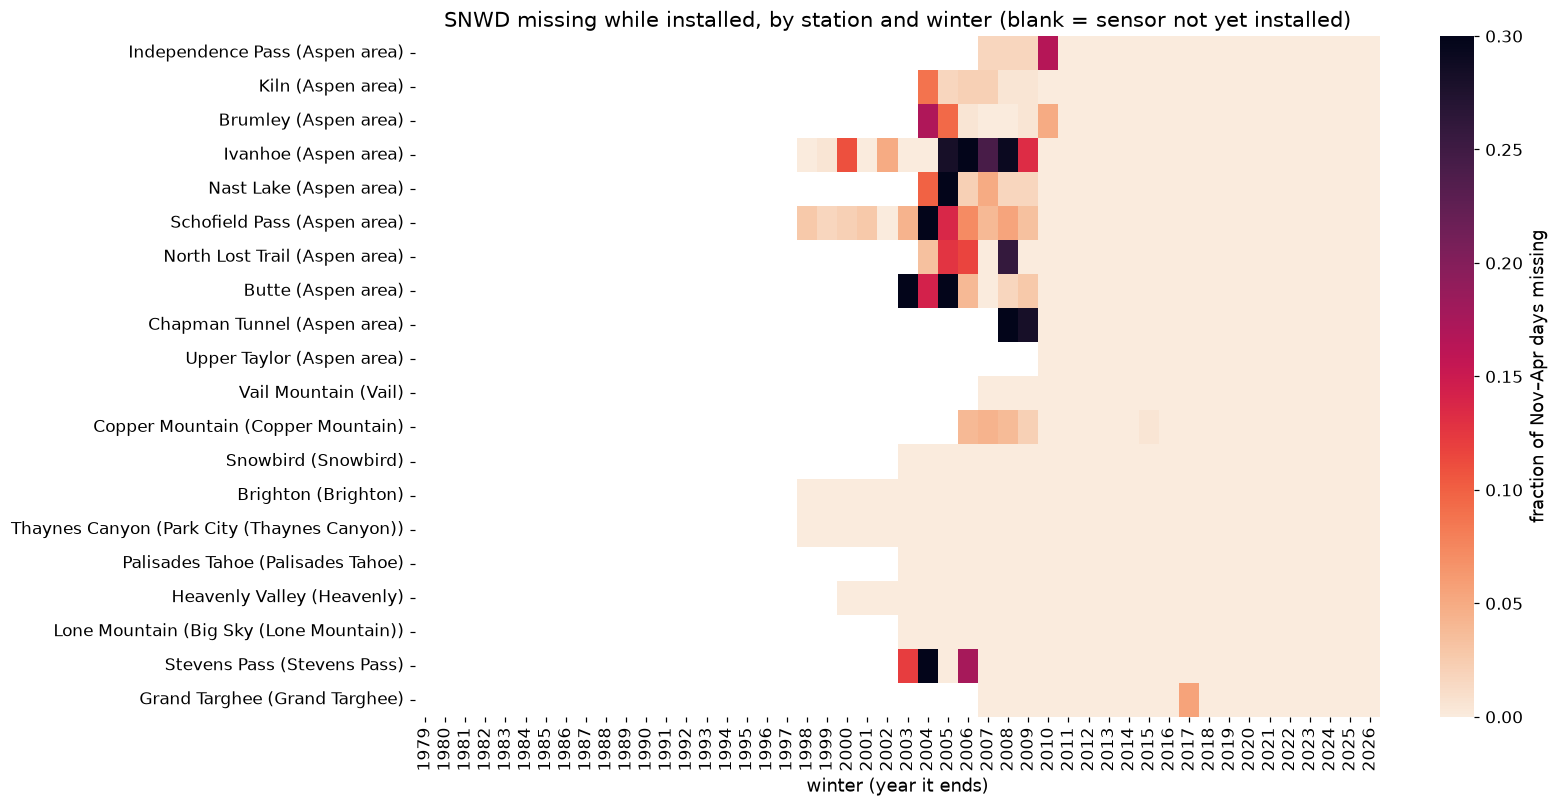

In [5]:
# Where does the in-season SNWD missingness sit? station x winter, among installed days
inst = installed_mask(w, "SNWD")
m = w[inst & w.in_season].assign(miss=lambda d: d.SNWD.isna())
grid = m.groupby([m.index.get_level_values("station"), "winter"])["miss"].mean().unstack("winter")
grid = grid.reindex(index=CAND, columns=range(1979, 2027))
grid.index = [f"{meta.loc[t, 'name']} ({meta.loc[t, 'group']})" for t in grid.index]
fig, ax = plt.subplots(figsize=(15, 7.5))
sns.heatmap(grid, cmap="rocket_r", vmin=0, vmax=0.3, ax=ax, cbar_kws={"label": "fraction of Nov–Apr days missing"},
            mask=grid.isna())
ax.set_title("SNWD missing while installed, by station and winter (blank = sensor not yet installed)")
ax.set_xlabel("winter (year it ends)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

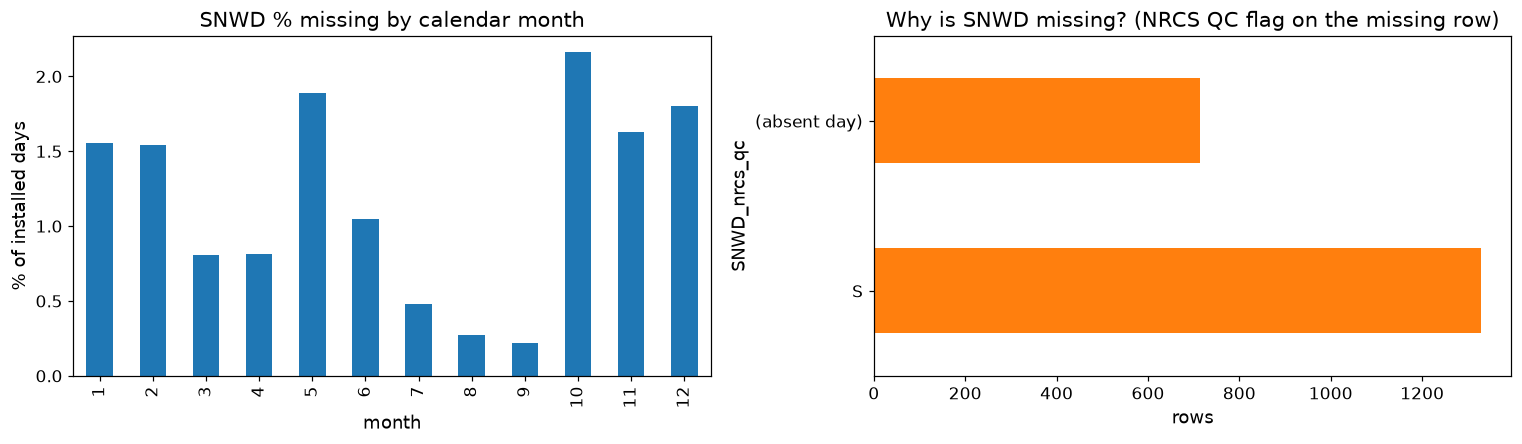

When SNWD is missing, TAVG is also missing on 35% of those days (whole-station outage vs sensor-only).
Mean SNWD the day BEFORE a missing day: 42.1 in vs all in-season days: 41.1 in


In [6]:
# Pattern checks for SNWD missingness (installed days only)
mi = w[inst].copy(); mi["miss"] = mi.SNWD.isna()
by_month = mi.groupby("month")["miss"].mean().mul(100)
by_flag = mi[mi.miss].SNWD_nrcs_qc.fillna("(absent day)").value_counts()
co_missing = mi.loc[mi.miss, "TAVG"].isna().mean() * 100
prev_depth = mi.groupby(level="station").SNWD.shift(1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
by_month.plot.bar(ax=axes[0], color="tab:blue")
axes[0].set_title("SNWD % missing by calendar month"); axes[0].set_xlabel("month"); axes[0].set_ylabel("% of installed days")
by_flag.plot.barh(ax=axes[1], color="tab:orange")
axes[1].set_title("Why is SNWD missing? (NRCS QC flag on the missing row)"); axes[1].set_xlabel("rows")
plt.tight_layout(); plt.show()
print(f"When SNWD is missing, TAVG is also missing on {co_missing:.0f}% of those days (whole-station outage vs sensor-only).")
print(f"Mean SNWD the day BEFORE a missing day: {prev_depth[mi.miss & mi.in_season].mean():.1f} in "
      f"vs all in-season days: {mi.loc[mi.in_season, 'SNWD'].mean():.1f} in")

**Interpretation (numbers above).**
- **Structural vs real.** 40% of SNWD rows are NaN, but almost all of that (39.8%) is days before the depth sensor was installed.
  Missing while installed is only **1.2% of days (2,043; 1.4% in Nov–Apr)**. Temperatures behave the same way (14% not installed, ~1.7% missing).
  WTEQ and precipitation are almost complete.
- **When.** The heatmap shows missingness concentrated in each depth sensor's **first few winters (≈2003–2010)**. After ~2011 it is near zero
  at every station, which suggests early sensor teething problems rather than anything weather-related.
- **Why.** Almost all missing SNWD rows carry NRCS flag **S**: NRCS removed the reading as suspect (§4).
- **Is it related to snow depth?** The mean depth the day before a gap (42.1 in) is about the same as the in-season mean (41.1 in), so we
  find **no evidence that gaps happen preferentially in deep snow**. Only 35% of SNWD gaps coincide with a temperature gap, so most are
  sensor-specific rather than whole-station outages. Given that, and the small amount, dropping or short-gap-filling (§6) is unlikely to bias the target.

## 4. NRCS quality flags: what we keep and what we drop
QC flags (NRCS definitions): **V** valid · **E** edited for sensor noise · **K** estimate · **S** suspect · **C** correction
equation applied · **N** no validation profile · **M** missing. Two codes, **G** and **T**, appear in the data but are **not
in the published NRCS list**; they are tallied below.

In [7]:
qc = (sn.assign(qc=sn.qc_flag.fillna("∅"), has_value=sn.value.notna())
        .groupby(["element", "qc", "has_value"]).size().unstack(["qc"], fill_value=0))
display(qc)
s_rows = sn[sn.qc_flag == "S"]
print("Suspect (S) rows: value present:", s_rows.value.notna().sum(), "| value null:", s_rows.value.isna().sum(),
      "| original reading present:", s_rows.orig_value.notna().sum())
print("Original readings behind SNWD 'S' rows (inches):", s_rows[s_rows.element == "SNWD"].orig_value.describe().round(1).to_dict())
print("\nUndocumented flags:")
display(sn[sn.qc_flag.isin(["G", "T"])].groupby(["station", "element", "qc_flag"])
        .agg(n=("value", "size"), first=("date", "min"), last=("date", "max"), min=("value", "min"), max=("value", "max")))

qc                      C       E  G    K     M   N     S    T       V
element has_value                                                     
PRCP    False           0       0  0    0  1002   0     0    0       0
        True            0  121195  0  199     0   0   363    0  162805
PREC    False           0       0  0    0    45   0   964    0       0
        True            0   91701  0  200     0   0   292    0  192380
SNWD    False           0       0  0    0     0   0  1721    0       0
        True            0   52844  0  472     0   0   113    0  116683
TAVG    False           0       0  0    0   267   0   784    0       0
        True       137011     798  7    9     0  58   492    0  103102
TMAX    False           0       0  0    0   218   0  1114    0       0
        True       136660     762  7    9     0   6   491    0  103260
TMIN    False           0       0  0    0   225   0   882    0       0
        True       136999     770  7    9     0   6   521    0  103111
WTEQ    False           0       0  0    0    34   0   261    0       0
        True            0  123784  0  437     0   0     0  523  160677

Suspect (S) rows: value present: 2272 | value null: 5726 | original reading present: 7723
Original readings behind SNWD 'S' rows (inches): {'count': 1834.0, 'mean': 80.8, 'std': 107.0, 'min': -280.0, '25%': 0.0, '50%': 47.0, '75%': 194.0, 'max': 269.0}

Undocumented flags:


n      first       last   min     max
station     element qc_flag                                         
518:CA:SNTL WTEQ    T        363 1979-05-31 1981-09-28   0.0     0.3
784:CA:SNTL WTEQ    T        160 1980-10-01 1993-04-18   0.0    99.9
842:CO:SNTL TAVG    G          7 1985-11-27 1985-12-05  37.4  2964.2
            TMAX    G          7 1985-11-27 1985-12-05  39.2  3349.4
            TMIN    G          7 1985-11-27 1985-12-05  44.6  2769.8

In [8]:
# Policy: S values -> NaN (NRCS has nulled almost all already; null the few that still carry a value).
for e in ELEMENTS:
    w[f"{e}_clean_flag"] = ""
    w[f"{e}_imputed"] = False
for e in ELEMENTS:
    msk = (w[f"{e}_nrcs_qc"] == "S") & w[e].notna()
    w.loc[msk, e] = np.nan; w.loc[msk, f"{e}_clean_flag"] += "S;"
    log("4", "NRCS QC flag S (suspect) still carrying a value", e, msk.sum(), "set NaN",
        "NRCS judged the reading suspect; the original is preserved in *_nrcs_orig")
log("4", "NRCS QC flag S with value already null", "all", (sn.qc_flag.eq("S") & sn.value.isna()).sum(), "keep NaN",
    "NRCS removed the value; we do NOT restore the original (originals behind S are physically implausible, e.g. ±200 in)")
log("4", "NRCS QC flags E/K/C (edited, estimated, corrected)", "all", sn.qc_flag.isin(["E", "K", "C"]).sum(), "keep",
    "NRCS corrections fix known sensor errors; flags kept per row so models can test sensitivity")
log("4", "undocumented flags G/T", "TAVG/TMAX/TMIN/WTEQ", sn.qc_flag.isin(["G", "T"]).sum(), "keep flag; values judged by §5 rules",
    "not in NRCS flag list; G rows (Vail 1985) contain ~3000 °F and are removed by the physical bounds in §5")

[4] NRCS QC flag S (suspect) still carrying a value | SNWD: 113 rows -> set NaN
[4] NRCS QC flag S (suspect) still carrying a value | WTEQ: 0 rows -> set NaN
[4] NRCS QC flag S (suspect) still carrying a value | TAVG: 492 rows -> set NaN
[4] NRCS QC flag S (suspect) still carrying a value | TMAX: 491 rows -> set NaN
[4] NRCS QC flag S (suspect) still carrying a value | TMIN: 521 rows -> set NaN
[4] NRCS QC flag S (suspect) still carrying a value | PREC: 292 rows -> set NaN
[4] NRCS QC flag S (suspect) still carrying a value | PRCP: 363 rows -> set NaN
[4] NRCS QC flag S with value already null | all: 5,726 rows -> keep NaN
[4] NRCS QC flags E/K/C (edited, estimated, corrected) | all: 803,859 rows -> keep
[4] undocumented flags G/T | TAVG/TMAX/TMIN/WTEQ: 544 rows -> keep flag; values judged by §5 rules


## 5. Unusual values: physically impossible, sensor artefacts, spikes
Every rule runs on source units (inches and °F) and records its rule ID in `<var>_clean_flag`. Each threshold comes from the
data distribution shown in that rule's cell.

### 5.1 Snow depth: negative values
Rule (in source inches): small negatives in [-4, 0) are a zero-offset on bare ground → 0; anything below -4 → NaN.
The raw data has 59 negative SNWD values (-2 to -4 in and around -60 in; see notebook 01 §2.6). **All of them carried NRCS flag S
and were already removed in §4**, so the rule below finds 0. It stays in as a guard for future downloads.

In [9]:
neg = w.SNWD[w.SNWD < 0]
print("negative SNWD values (in):", neg.value_counts().sort_index().to_dict())
m_small = (w.SNWD < 0) & (w.SNWD >= -4)
m_big = w.SNWD < -4
w.loc[m_small, "SNWD"] = 0.0; w.loc[m_small, "SNWD_clean_flag"] += "neg_offset;"
log("5.1", "SNWD in [-4, 0) in", "SNWD", m_small.sum(), "set 0",
    "ultrasonic zero-offset: small negatives cluster at -2..-4 in on bare ground")
w.loc[m_big, "SNWD"] = np.nan; w.loc[m_big, "SNWD_clean_flag"] += "neg_large;"
log("5.1", "SNWD < -4 in", "SNWD", m_big.sum(), "set NaN", "impossible; values ~ -60 in are sensor errors")

negative SNWD values (in): {}
[5.1] SNWD in [-4, 0) in | SNWD: 0 rows -> set 0
[5.1] SNWD < -4 in | SNWD: 0 rows -> set NaN


### 5.2 Snow depth: one- or two-day spikes
**Rule:** residual from a centred 7-day rolling median. A storm or melt-out is a *step*, and the median follows a step
within 3 days, so steps leave small residuals. A sensor spike that reverts leaves a large one. The threshold sits in the
gap of the residual distribution below.

In [10]:
res = clean.rolling_median_residual(w.SNWD, 7)
bins = [-300, -30, -20, -12, -6, 6, 12, 20, 30, 300]
display(pd.cut(res[res.abs() > 6], bins).value_counts().sort_index().to_frame("n days").T)
print("|residual| quantiles (in):", res.abs().quantile([.99, .999, .9999]).round(1).to_dict())
SPIKE_IN = 20
spk = res.abs() > SPIKE_IN
w["SNWD_pre_spike"] = w.SNWD
w.loc[spk, "SNWD"] = np.nan; w.loc[spk, "SNWD_clean_flag"] += "spike;"
log("5.2", f"|SNWD - rolling median(7d)| > {SPIKE_IN} in", "SNWD", spk.sum(), "set NaN",
    "residual histogram has its minimum in the 20–30 in bin, between storm/settlement deviations (≤20 in) and the spike tail (>30 in); 99.99th pct = 37 in")

SNWD,"(-300, -30]","(-30, -20]","(-20, -12]","(-12, -6]","(-6, 6]","(6, 12]","(12, 20]","(20, 30]","(30, 300]"
n days,21,2,7,141,0,838,46,5,2


|residual| quantiles (in): {0.99: 6.0, 0.999: 11.0, 0.9999: 37.0}
[5.2] |SNWD - rolling median(7d)| > 20 in | SNWD: 28 rows -> set NaN


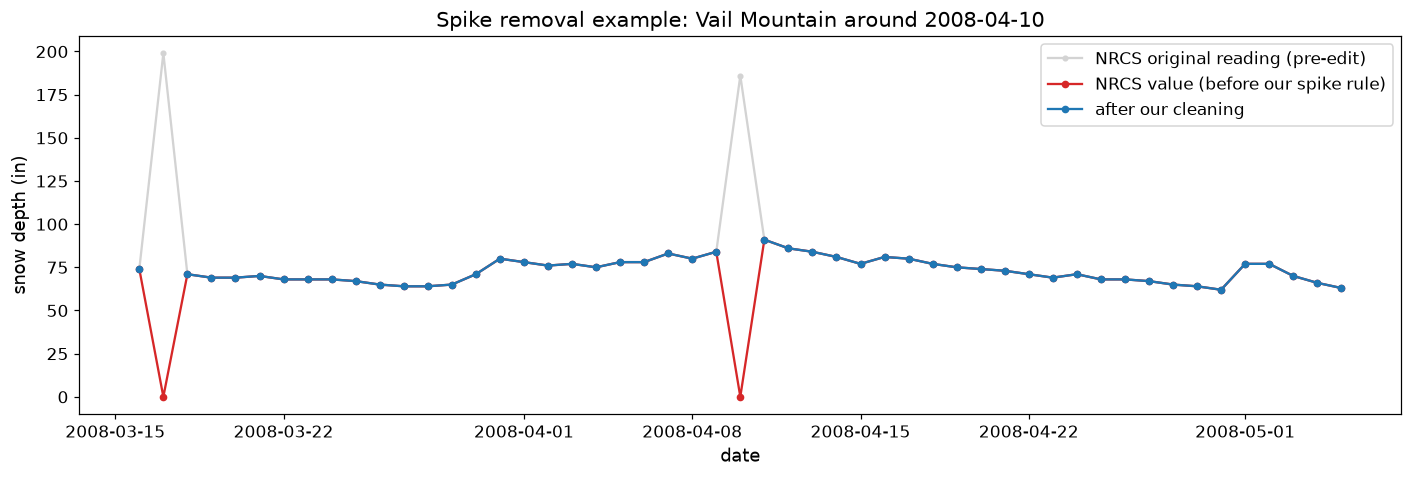

In [11]:
# Before/after example: the station-day with the largest flagged spike, ±25 days
(st, day) = res[spk].abs().idxmax()
win = slice(day - pd.Timedelta(days=25), day + pd.Timedelta(days=25))
d = w.loc[st].loc[win]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(d.index, d.SNWD_nrcs_orig, "o-", ms=3, color="lightgrey", label="NRCS original reading (pre-edit)")
ax.plot(d.index, d.SNWD_pre_spike, "o-", ms=4, color="tab:red", label="NRCS value (before our spike rule)")
ax.plot(d.index, d.SNWD, "o-", ms=4, color="tab:blue", label="after our cleaning")
ax.set_title(f"Spike removal example: {meta.loc[st, 'name']} around {day.date()}")
ax.set_ylabel("snow depth (in)"); ax.set_xlabel("date"); ax.legend()
plt.tight_layout(); plt.show()
w = w.drop(columns="SNWD_pre_spike")

### 5.3 Snow-water equivalent spikes
The same method applied to WTEQ. The snow pillow is much smoother than the depth sensor.

In [12]:
rw = clean.rolling_median_residual(w.WTEQ, 7)
display(pd.cut(rw[rw.abs() > 1], [-300, -10, -5, -2, -1, 1, 2, 5, 10, 300]).value_counts().sort_index().to_frame("n days").T)
WSPIKE_IN = 5
m = rw.abs() > WSPIKE_IN
w.loc[m, "WTEQ"] = np.nan; w.loc[m, "WTEQ_clean_flag"] += "spike;"
log("5.3", f"|WTEQ - rolling median(7d)| > {WSPIKE_IN} in", "WTEQ", m.sum(), "set NaN",
    "pillow residuals are almost all ≤ 2 in; > 5 in is isolated")

WTEQ,"(-300, -10]","(-10, -5]","(-5, -2]","(-2, -1]","(-1, 1]","(1, 2]","(2, 5]","(5, 10]","(10, 300]"
n days,1,0,12,147,0,117,29,1,0


[5.3] |WTEQ - rolling median(7d)| > 5 in | WTEQ: 2 rows -> set NaN


### 5.4 Depth vs SWE consistency (snow density = WTEQ / SNWD)
- Depth smaller than SWE means density > 1, which is impossible. **Rule:** SNWD → NaN when SNWD < WTEQ and WTEQ ≥ 1 in. We
  distrust the depth sensor because the pillow is smoother (§5.3).
- Depth = 0 while the pillow holds > 4 in of SWE, in season, means the depth sensor dropped out. **Rule:** SNWD → NaN.
- Density between 0.7 and 1 is implausible (old spring snow peaks at ~0.5–0.6) but not impossible: flag it, keep it.

In [13]:
dens = w.WTEQ / w.SNWD
q = dens[(w.SNWD >= 4) & (w.WTEQ > 0)].quantile([.001, .01, .05, .5, .95, .99, .999]).round(3)
print("density quantiles where depth ≥ 4 in:", q.to_dict())
m1 = (w.SNWD < w.WTEQ) & (w.WTEQ >= 1)
w.loc[m1, "SNWD"] = np.nan; w.loc[m1, "SNWD_clean_flag"] += "density>1;"
log("5.4", "SNWD < WTEQ (density > 1) with WTEQ ≥ 1 in", "SNWD", m1.sum(), "set NaN", "physically impossible")
m2 = (w.SNWD == 0) & (w.WTEQ > 4) & w.in_season
w.loc[m2, "SNWD"] = np.nan; w.loc[m2, "SNWD_clean_flag"] += "zero_with_swe;"
log("5.4", "SNWD = 0 while WTEQ > 4 in (Nov–Apr)", "SNWD", m2.sum(), "set NaN", "depth-sensor dropout")
m3 = ((w.WTEQ / w.SNWD) > 0.7) & (w.SNWD >= 4)
w.loc[m3, "SNWD_clean_flag"] += "dense_0.7-1;"
log("5.4", "density in (0.7, 1]", "SNWD", m3.sum(), "flag only (keep)", "implausible but not impossible")

density quantiles where depth ≥ 4 in: {0.001: 0.06, 0.01: 0.112, 0.05: 0.162, 0.5: 0.282, 0.95: 0.493, 0.99: 0.576, 0.999: 0.7}
[5.4] SNWD < WTEQ (density > 1) with WTEQ ≥ 1 in | SNWD: 134 rows -> set NaN
[5.4] SNWD = 0 while WTEQ > 4 in (Nov–Apr) | SNWD: 0 rows -> set NaN
[5.4] density in (0.7, 1] | SNWD: 82 rows -> flag only (keep)


### 5.5 Summer "snow" on bare ground
In Jul–Sep the pillow often reads 0 SWE while the ultrasonic depth sensor reports a few inches, because it is
measuring vegetation. **Rule:** Jul–Sep, WTEQ = 0 and SNWD > 0 → SNWD = 0. This sits outside the Nov–Apr window, but it
keeps derived features such as "days since snow-on" honest.

In [14]:
summer = w.month.isin([7, 8, 9])
m = summer & (w.WTEQ == 0) & (w.SNWD > 0)
print("SNWD on those days (in):", w.loc[m, "SNWD"].describe().round(1).to_dict())
w.loc[m, "SNWD"] = 0.0; w.loc[m, "SNWD_clean_flag"] += "summer_noise;"
log("5.5", "Jul–Sep, WTEQ = 0 and SNWD > 0", "SNWD", m.sum(), "set 0", "ultrasonic sensor sees vegetation; pillow is empty")

SNWD on those days (in): {'count': 878.0, 'mean': 4.7, 'std': 4.4, 'min': 1.0, '25%': 1.0, '50%': 3.0, '75%': 6.0, 'max': 24.0}
[5.5] Jul–Sep, WTEQ = 0 and SNWD > 0 | SNWD: 878 rows -> set 0


### 5.6 Temperatures: stuck loggers, sentinel values, physical bounds, spikes, internal consistency

In [15]:
T3 = ["TAVG", "TMAX", "TMIN"]
# (a) stuck logger: the identical value repeated for days. Real air temperature never repeats exactly (0.1 °F) for 5+ days.
STUCK_DAYS = 5
for c in T3:
    rl = clean.constant_run_lengths(w[c])
    if c == "TAVG":
        print("TAVG: days inside runs of identical values, by minimum run length:",
              {k: int((rl >= k).sum()) for k in (2, 3, 4, 5, 7, 10)}, "(plateau from 5 on = long flat lines)")
    m = (rl >= STUCK_DAYS) & w[c].notna()
    w.loc[m, c] = np.nan; w.loc[m, f"{c}_clean_flag"] += "stuck;"
    log("5.6", f"{c} identical for ≥ {STUCK_DAYS} consecutive days", c, m.sum(), "set NaN",
        "flat-lined logger (e.g. Stevens Pass Aug 1989: TMIN -29 °C for 12 days); count barely changes from 5 to 10+ days")
vc = pd.concat([w[c] for c in T3]).round(1).value_counts()
print("Most common temps below -50 °F (a repeated exact value suggests a sensor floor/sentinel):",
      vc[vc.index < -50].head(5).to_dict())
LO_F, HI_F = -50, 100
for c in T3:
    m = (w[c] < LO_F) | (w[c] > HI_F)
    w.loc[m, c] = np.nan; w.loc[m, f"{c}_clean_flag"] += "bounds;"
    log("5.6", f"{c} outside [{LO_F}, {HI_F}] °F", c, m.sum(), "set NaN",
        "-60.3 °F repeats hundreds of times (sensor floor sentinel); thousands of °F are logger garbage (e.g. Vail 1985, flag G)")
TSPIKE_F = 30
for c in T3:
    r = clean.rolling_median_residual(w[c], 7)
    if c == "TAVG":
        print("TAVG |residual| quantiles (°F):", r.abs().quantile([.99, .999, .9999]).round(1).to_dict())
    m = r.abs() > TSPIKE_F
    w.loc[m, c] = np.nan; w.loc[m, f"{c}_clean_flag"] += "spike;"
    log("5.6", f"|{c} - rolling median(7d)| > {TSPIKE_F} °F", c, m.sum(), "set NaN",
        "99.9th pct of residual is ~24 °F; > 30 °F persists for only 1–2 days = sensor glitch")
m = w.TMIN > w.TMAX
for c in ["TMIN", "TMAX"]:
    w.loc[m, c] = np.nan; w.loc[m, f"{c}_clean_flag"] += "tmin>tmax;"
log("5.6", "TMIN > TMAX", "TMIN,TMAX", m.sum(), "set both NaN", "impossible")
m = (w.TAVG < w.TMIN - 1) | (w.TAVG > w.TMAX + 1)
w.loc[m, "TAVG"] = np.nan; w.loc[m, "TAVG_clean_flag"] += "outside_minmax;"
log("5.6", "TAVG outside [TMIN-1, TMAX+1] °F", "TAVG", m.sum(), "set NaN", "average must lie between min and max (1 °F tolerance for rounding)")

TAVG: days inside runs of identical values, by minimum run length: {2: 10190, 3: 1666, 4: 1360, 5: 1324, 7: 1301, 10: 1287} (plateau from 5 on = long flat lines)


[5.6] TAVG identical for ≥ 5 consecutive days | TAVG: 1,324 rows -> set NaN
[5.6] TMAX identical for ≥ 5 consecutive days | TMAX: 1,322 rows -> set NaN


[5.6] TMIN identical for ≥ 5 consecutive days | TMIN: 1,333 rows -> set NaN
Most common temps below -50 °F (a repeated exact value suggests a sensor floor/sentinel): {-60.3: 90, -58.0: 8, -54.4: 7, -60.5: 6, -54.2: 3}
[5.6] TAVG outside [-50, 100] °F | TAVG: 46 rows -> set NaN
[5.6] TMAX outside [-50, 100] °F | TMAX: 160 rows -> set NaN
[5.6] TMIN outside [-50, 100] °F | TMIN: 54 rows -> set NaN
TAVG |residual| quantiles (°F): {0.99: 14.9, 0.999: 21.2, 0.9999: 27.9}
[5.6] |TAVG - rolling median(7d)| > 30 °F | TAVG: 15 rows -> set NaN


[5.6] |TMAX - rolling median(7d)| > 30 °F | TMAX: 133 rows -> set NaN


[5.6] |TMIN - rolling median(7d)| > 30 °F | TMIN: 64 rows -> set NaN


[5.6] TMIN > TMAX | TMIN,TMAX: 40 rows -> set both NaN


[5.6] TAVG outside [TMIN-1, TMAX+1] °F | TAVG: 10 rows -> set NaN


**Daily temperature range (TMAX − TMIN).** The [-50, 100] °F bounds still pass days like Butte, 2003-04-28: a 99 °F maximum
against a 32 °F minimum, in April at 10,190 ft. A real 99 °F *is* possible at a lower station: Stevens Pass hit it on 2021-06-29
during the Pacific Northwest heat dome. So a tighter fixed bound would delete real weather. Instead we test the daily
range. Its distribution decays smoothly up to its 99.9th percentile (~35 °C), then **flattens**: almost as many days fall in 35–40 °C as in 40–70 °C. That
flat tail is the signature of sensor faults, typically a sun-heated radiation shield inflating TMAX. Large ranges at Nast Lake
(a valley-floor station with cold-air pooling) mostly fall below 35 °C and are kept.

In [16]:
dtr_c = (w.TMAX - w.TMIN) * 5 / 9
print("daily range quantiles (°C):", dtr_c.quantile([.5, .99, .999, .9999]).round(1).to_dict())
display(pd.cut(dtr_c[dtr_c > 20], [20, 25, 30, 35, 40, 70]).value_counts().sort_index().to_frame("n days").T)
DTR_C = 35
m = dtr_c > DTR_C
print("by station:", w[m].index.get_level_values("station").map(meta["name"]).value_counts().to_dict())
w.loc[m, "TMAX"] = np.nan; w.loc[m, "TMAX_clean_flag"] += "dtr>35C;"
log("5.6", f"TMAX - TMIN > {DTR_C} °C", "TMAX", m.sum(), "set TMAX NaN",
    "range distribution flattens beyond its 99.9th pct (~35 °C) = sensor artefact (radiation-heated TMAX); heat-dome days at Stevens Pass have normal ranges and are kept")
# The same fault inflates TAVG (computed from the same hourly sensor). With TMAX now NaN, the
# "TAVG within [TMIN, TMAX]" check can no longer catch it, so test the mean against the minimum instead.
gap_c = (w.TAVG - w.TMIN) * 5 / 9
print("TAVG - TMIN quantiles (°C):", gap_c.quantile([.5, .99, .999, .9999]).round(1).to_dict())
display(pd.cut(gap_c[gap_c > 12], [12, 15, 18, 20, 22, 25, 30, 40]).value_counts().sort_index().to_frame("n days").T)
TAVG_MIN_C = 20
m = gap_c > TAVG_MIN_C
print(f"of which TMAX already removed as faulty: {int((m & w.TMAX.isna()).sum())} / {int(m.sum())}")
w.loc[m, "TAVG"] = np.nan; w.loc[m, "TAVG_clean_flag"] += "tavg-tmin>20C;"
log("5.6", f"TAVG - TMIN > {TAVG_MIN_C} °C", "TAVG", m.sum(), "set NaN",
    "99.9th pct is ~18 °C; tail flattens beyond 20 °C and is dominated by days whose TMAX was already faulty (e.g. Nast Lake Aug–Sep 2005, TAVG 37 °C)")

daily range quantiles (°C): {0.5: 13.2, 0.99: 27.0, 0.999: 33.4, 0.9999: 45.1}


,"(20, 25]","(25, 30]","(30, 35]","(35, 40]","(40, 70]"
n days,19941,4383,494,98,81


by station: {'Schofield Pass': 65, 'Butte': 64, 'Nast Lake': 46, 'North Lost Trail': 3, 'Kiln': 1}
[5.6] TMAX - TMIN > 35 °C | TMAX: 179 rows -> set TMAX NaN
TAVG - TMIN quantiles (°C): {0.5: 5.7, 0.99: 13.1, 0.999: 17.1, 0.9999: 30.4}


,"(12, 15]","(15, 18]","(18, 20]","(20, 22]","(22, 25]","(25, 30]","(30, 40]"
n days,3964,407,72,32,36,28,26


of which TMAX already removed as faulty: 111 / 122
[5.6] TAVG - TMIN > 20 °C | TAVG: 122 rows -> set NaN


### 5.7 Precipitation
`PREC` is precipitation accumulated since Oct 1, and it resets each water year. `PRCP` is the daily increment.

In [17]:
m = w.PRCP < 0
w.loc[m, "PRCP"] = np.nan; w.loc[m, "PRCP_clean_flag"] += "negative;"
log("5.7", "PRCP < 0", "PRCP", m.sum(), "set NaN", "daily precipitation cannot be negative")
dp = w.groupby([w.index.get_level_values("station"), "water_year"]).PREC.diff()
m = dp < -0.05
w.loc[m, "PREC_clean_flag"] += "decrease;"
log("5.7", "PREC decreases within a water year", "PREC", m.sum(), "flag only",
    "accumulated precip should not fall; drops are 0.1 in (gauge noise) — PRCP already encodes the increments")
print("PRCP max (in/day):", w.PRCP.max(), "| top 5:", w.PRCP.nlargest(5).round(2).tolist())

[5.7] PRCP < 0 | PRCP: 0 rows -> set NaN
[5.7] PREC decreases within a water year | PREC: 8 rows -> flag only
PRCP max (in/day): 9.0 | top 5: [9.0, 8.3, 7.8, 7.7, 7.4]


## 6. Missing-value handling: causal fill of short gaps only
**Decision:** **forward-fill** (carry the last valid value) across **interior** gaps of ≤ 3 days in SNWD, WTEQ, TAVG, TMAX and TMIN, per
station. Longer gaps stay entirely NaN and are never partially filled, as do gaps before or after a station's record. PRCP/PREC are
not imputed, because precipitation is intermittent and carrying it forward would invent it. Every imputed value has `<var>_imputed = True`.

**Why forward-fill rather than interpolation?** Linear interpolation uses the value *after* the gap, so an interpolated "today" would
contain future information. That is leakage if it is used as a feature. A forward-filled value equals the last real reading at or before that
day, so it is **safe to use as a feature by construction** (unit-tested in `tests/test_clean.py::test_ffill_is_causal_in_values`).
One caveat: *whether* a gap qualifies ("it ends within 3 days") is judged from the missingness pattern, but no future *value* enters
any filled cell. **Rows whose target (SNWD) was imputed are still excluded from training labels and evaluation**, so the model is never
scored against a filled value.
Justification, gap-length distribution:

In [18]:
rows = []
for e in ["SNWD", "WTEQ", "TAVG", "TMAX", "TMIN"]:
    inst = installed_mask(w, e)
    runs = clean.nan_run_lengths(w[e])[inst & w[e].isna()]
    # one entry per gap: take run length at gap starts
    starts = runs[(runs > 0)]
    gaps = starts.groupby(level="station").apply(lambda s: s[(s.index.get_level_values("date").to_series().diff().dt.days != 1).to_numpy()])
    gl = gaps.to_numpy()
    rows.append({"var": e, "n gaps": len(gl), "% gaps ≤1 d": 100 * (gl <= 1).mean(), "% gaps ≤3 d": 100 * (gl <= 3).mean(),
                 "% gaps ≤7 d": 100 * (gl <= 7).mean(), "% of missing DAYS in gaps ≤3 d": 100 * gl[gl <= 3].sum() / gl.sum(),
                 "longest gap (d)": gl.max() if len(gl) else 0})
display(pd.DataFrame(rows).set_index("var").round(1))
MAX_GAP = 3
for e in ["SNWD", "WTEQ", "TAVG", "TMAX", "TMIN"]:
    w[e], imp = clean.ffill_short_gaps(w[e], MAX_GAP)
    w[f"{e}_imputed"] = imp
    log("6", f"forward-fill interior gaps ≤ {MAX_GAP} d", e, imp.sum(), "causal forward fill (last valid value)",
        "state variables change little over 1–3 days; causal fill carries no future information, so it is safe as a feature; longer gaps left NaN")

,n gaps,% gaps ≤1 d,% gaps ≤3 d,% gaps ≤7 d,% of missing DAYS in gaps ≤3 d,longest gap (d)
var,,,,,,
SNWD,886,65.6,87.6,95.5,44.4,79
WTEQ,8,50.0,62.5,75.0,18.9,15
TAVG,1110,69.5,87.0,92.9,24.1,365
TMAX,1229,69.5,85.9,92.1,23.3,365
TMIN,1286,74.9,90.5,94.4,27.8,365


[6] forward-fill interior gaps ≤ 3 d | SNWD: 1,029 rows -> causal forward fill (last valid value)


[6] forward-fill interior gaps ≤ 3 d | WTEQ: 7 rows -> causal forward fill (last valid value)


[6] forward-fill interior gaps ≤ 3 d | TAVG: 1,218 rows -> causal forward fill (last valid value)


[6] forward-fill interior gaps ≤ 3 d | TMAX: 1,313 rows -> causal forward fill (last valid value)
[6] forward-fill interior gaps ≤ 3 d | TMIN: 1,420 rows -> causal forward fill (last valid value)


## 7. Units, final columns, and missingness after cleaning
Conversions: inches → cm (×2.54) for depth and SWE, inches → mm (×25.4) for precipitation, °F → °C.
The NRCS original values (`*_nrcs_orig`) stay in **source units** (in / °F), as the data dictionary records.

In [19]:
out = pd.DataFrame(index=w.index)
out["winter"] = w.winter; out["water_year"] = w.water_year; out["in_season"] = w.in_season
out["SNWD_cm"] = w.SNWD * clean.IN_TO_CM
out["WTEQ_cm"] = w.WTEQ * clean.IN_TO_CM
for c in ["TAVG", "TMAX", "TMIN"]:
    out[f"{c}_C"] = clean.f_to_c(w[c])
out["PRCP_mm"] = w.PRCP * clean.IN_TO_MM
out["PREC_mm"] = w.PREC * clean.IN_TO_MM
for e in ELEMENTS:
    for suf in ["clean_flag", "imputed", "nrcs_qc", "nrcs_qa", "nrcs_orig"]:
        out[f"{e}_{suf}"] = w[f"{e}_{suf}"]
out = out.reset_index()
out.insert(1, "station_name", out.station.map(meta["name"]))
out.insert(2, "group", out.station.map(meta["group"]))
for c in out.columns:
    if c.endswith(("_nrcs_qc", "_nrcs_qa", "_clean_flag")):
        out[c] = out[c].astype("string")
log("7", "unit conversion", "all value columns", len(out), "in→cm/mm, °F→°C", "SI units for modelling; originals kept in source units")

VALUE_COLS = ["SNWD_cm", "WTEQ_cm", "TAVG_C", "TMAX_C", "TMIN_C", "PRCP_mm", "PREC_mm"]
after = pd.DataFrame({
    "% NaN (all rows)": out[VALUE_COLS].isna().mean() * 100,
    "% NaN Nov–Apr": out.loc[out.in_season, VALUE_COLS].isna().mean() * 100}).round(2)
before = miss_raw["% rows NaN (all)"].rename(lambda e: [c for c in VALUE_COLS if c.startswith(e)][0])
after.insert(0, "% NaN before cleaning (all rows)", before.round(2))
print(out.shape); after

[7] unit conversion | all value columns: 285,778 rows -> in→cm/mm, °F→°C
(285778, 49)


,% NaN before cleaning (all rows),% NaN (all rows),% NaN Nov–Apr
SNWD_cm,40.47,40.21,40.25
WTEQ_cm,0.12,0.12,0.02
TAVG_C,15.50,15.78,15.49
TMAX_C,15.60,15.95,15.71
TMIN_C,15.52,15.73,15.44
PRCP_mm,0.43,0.55,0.36
PREC_mm,0.42,0.52,0.34


## 8. The target: distribution, zeros, and the class-imbalance question
Our task is **regression** (snow depth in cm), so class imbalance in the classification sense doesn't apply. The
analogous concern is the target's shape. In-season snow depth has a **spike at zero** (early and late season, and low stations) and
a long right tail (big winters). That matters for metric choice: MAE vs RMSE, and per-month reporting.

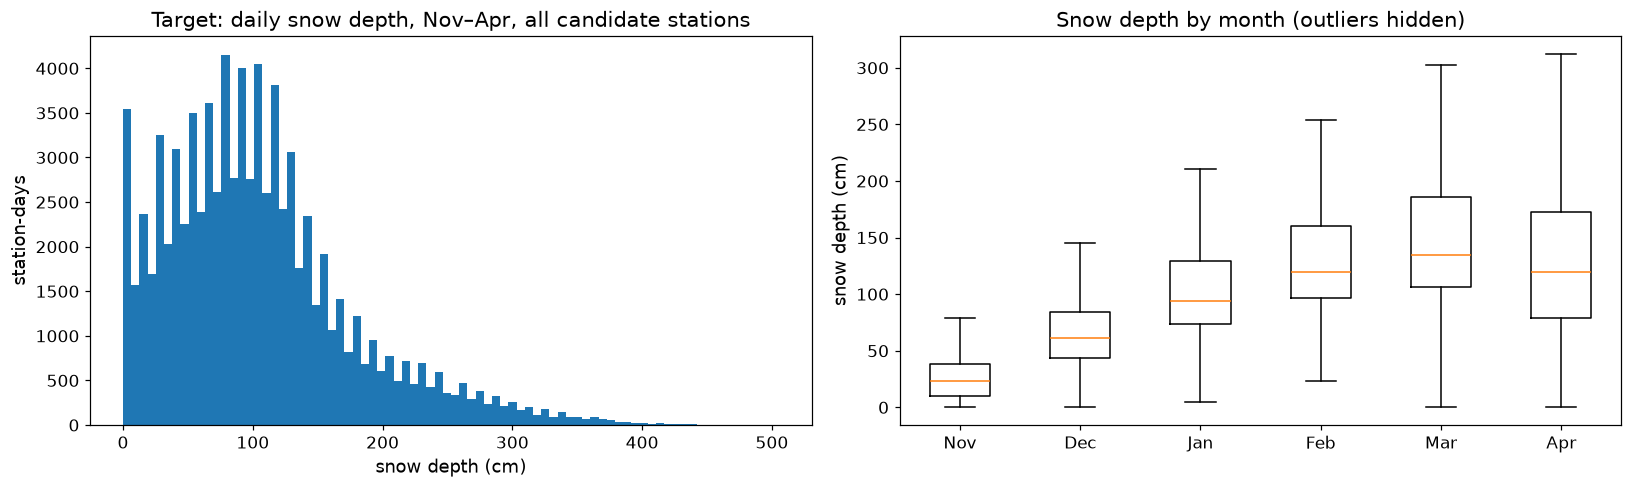

Overall: 84,261 target station-days, 2.5% zero, skew 1.07


,group,n_days,pct_zero,median_cm,p95_cm,skew
station_name,,,,,,
Grand Targhee,Grand Targhee,3615,0.0,213.4,332.7,-0.2
Ivanhoe,Aspen area,4984,0.0,96.5,154.9,-0.1
Schofield Pass,Aspen area,5089,0.4,149.9,276.9,0.1
Lone Mountain,Big Sky (Lone Mountain),4350,0.5,99.1,172.7,0.1
Chapman Tunnel,Aspen area,3324,0.6,81.3,139.7,-0.0
Snowbird,Snowbird,4350,0.9,157.5,332.7,0.4
Independence Pass,Aspen area,3584,1.0,96.5,157.5,-0.1
Thaynes Canyon,Park City (Thaynes Canyon),5256,1.1,109.2,221.0,0.3
Copper Mountain,Copper Mountain,3776,1.2,88.9,149.9,-0.1


In [20]:
tg = out[out.in_season & out.SNWD_cm.notna() & ~out.SNWD_imputed]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].hist(tg.SNWD_cm, bins=80, color="tab:blue")
axes[0].set_title("Target: daily snow depth, Nov–Apr, all candidate stations"); axes[0].set_xlabel("snow depth (cm)"); axes[0].set_ylabel("station-days")
by_m = tg.assign(m=tg.date.dt.month).groupby("m").SNWD_cm
order = [11, 12, 1, 2, 3, 4]
axes[1].boxplot([by_m.get_group(k) for k in order], tick_labels=["Nov", "Dec", "Jan", "Feb", "Mar", "Apr"], showfliers=False)
axes[1].set_title("Snow depth by month (outliers hidden)"); axes[1].set_ylabel("snow depth (cm)")
plt.tight_layout(); plt.show()
z = tg.groupby("station_name").agg(group=("group", "first"), n_days=("SNWD_cm", "size"),
                                   pct_zero=("SNWD_cm", lambda s: 100 * (s == 0).mean()),
                                   median_cm=("SNWD_cm", "median"), p95_cm=("SNWD_cm", lambda s: s.quantile(.95)),
                                   skew=("SNWD_cm", "skew"))
print(f"Overall: {len(tg):,} target station-days, {100 * (tg.SNWD_cm == 0).mean():.1f}% zero, skew {tg.SNWD_cm.skew():.2f}")
z.round(1).sort_values("pct_zero")

## 9. Scale of the features

In [21]:
scale = out[VALUE_COLS].describe(percentiles=[.01, .5, .99]).T
scale["range"] = scale["max"] - scale["min"]
scale.round(2)

,count,mean,std,min,1%,50%,99%,max,range
SNWD_cm,170866.0,59.26,74.83,0.00,0.00,25.40,304.80,505.46,505.46
WTEQ_cm,285426.0,19.76,29.90,0.00,0.00,6.35,133.86,295.91,295.91
TAVG_C,240686.0,1.80,8.77,-31.28,-17.11,1.61,18.28,28.22,59.50
TMAX_C,240183.0,9.25,9.63,-25.78,-11.00,9.11,27.22,37.78,63.56
TMIN_C,240831.0,-4.05,8.79,-36.39,-24.61,-3.39,13.50,20.89,57.28
PRCP_mm,284199.0,2.67,6.58,0.00,0.00,0.00,30.48,228.60,228.60
PREC_mm,284281.0,566.04,483.58,0.00,0.00,477.52,2339.34,3403.60,3403.60


The columns are on very different scales: snow depth runs to hundreds of cm, while temperature is a few tens of °C around zero. Models that are
sensitive to scale (regularised linear regression, kNN) need standardisation. **The scaler must be fit on training winters only**
(§10). Tree models don't need scaling.

## 10. Information leakage
| Risk | Where it could enter | Handling |
|---|---|---|
| Future data in features | rolling/lagged features | features for a prediction made on day *t* use only rows dated ≤ *t* (target is *t*+30) |
| Test winters in the baseline | climatology | per-day-of-season climatology computed from **training winters only** (staff condition) |
| NRCS 30-year normals | API `centralTendencyType` | never requested (D-010): 1991–2020 normals include test winters |
| Scaling / imputation fit on all data | standardisation, gap filling | scalers fit on training winters only. Gap filling is **causal** (forward fill ≤ 3 d, §6), so filled values contain no future information; imputed target rows are excluded from labels and evaluation |
| **NRCS edits and approvals are made after the fact** | `value` vs `orig_value`, QA flag A | see below |
| Season-accumulated `PREC` | resets each Oct 1 | features use PRCP sums over trailing windows, not raw PREC across a reset |

**Post-hoc edits.** On a real prediction date, a forecaster would only have the raw, provisional reading. The `value`
we train on has often been edited by NRCS weeks or months later using later readings. The QA flag "A" (approved) is applied at
end-of-season review. So our "today's snow depth" feature is slightly cleaner than it could really be. The table below shows
how much this matters. **Mitigation:** a robustness check in modelling that rebuilds the day-*t* features from
`*_nrcs_orig` (the raw readings) and compares accuracy.

In [22]:
ed = sn[sn.element.isin(["SNWD", "WTEQ"]) & sn.value.notna() & sn.orig_value.notna()].copy()
ed["edited"] = ed.value != ed.orig_value
ed["winter"] = parse.winter_of(ed.date)
print("Share of values changed by NRCS after the reading:", ed.groupby("element").edited.mean().mul(100).round(1).to_dict(), "%")
print("Median |edit| where edited (in):", ed[ed.edited].assign(d=lambda d: (d.value - d.orig_value).abs()).groupby("element").d.median().to_dict())
qa = sn[sn.element == "SNWD"].assign(winter=lambda d: parse.winter_of(d.date))
qa_share = qa.groupby("winter").qa_flag.value_counts(normalize=True, dropna=False).unstack(fill_value=0).mul(100)
print("\nSNWD QA status by winter (% of values). NaN = no QA flag recorded (older data predates QA flagging);"
      " the most recent winters are mostly P (provisional) -> NRCS may still revise them")
qa_share.loc[2018:].round(1)

Share of values changed by NRCS after the reading: {'SNWD': 29.2, 'WTEQ': 33.7} %


Median |edit| where edited (in): {'SNWD': 1.0, 'WTEQ': 0.2}

SNWD QA status by winter (% of values). NaN = no QA flag recorded (older data predates QA flagging); the most recent winters are mostly P (provisional) -> NRCS may still revise them


qa_flag,A,P,NaN
winter,,,
2018,0.0,0.0,100.0
2019,0.0,0.0,100.0
2020,0.0,0.0,100.0
2021,0.0,0.0,100.0
2022,0.0,0.0,100.0
2023,3.8,0.0,96.2
2024,68.9,7.5,23.6
2025,75.0,25.0,0.0
2026,28.7,71.3,0.0


## 11. Save outputs, data dictionary and cleaning log

In [23]:
DICT = []
def dd(col, desc, unit=""):
    DICT.append({"column": col, "description": desc, "unit": unit})
dd("station", "SNOTEL station triplet (id:state:network)"); dd("station_name", "NRCS station name"); dd("group", "resort group from src/sites.py")
dd("date", "observation date (AWDB periodRef=END)"); dd("winter", "season label = year the winter ends (Jul–Dec -> next year)")
dd("water_year", "Oct 1 – Sep 30, labelled by end year (PREC resets)"); dd("in_season", "Nov 1 – Apr 30")
for c, d_, u in [("SNWD_cm", "snow depth (target)", "cm"), ("WTEQ_cm", "snow-water equivalent", "cm"), ("TAVG_C", "daily mean air temp", "°C"),
                 ("TMAX_C", "daily max air temp", "°C"), ("TMIN_C", "daily min air temp", "°C"), ("PRCP_mm", "daily precipitation increment", "mm"),
                 ("PREC_mm", "precipitation accumulated since Oct 1", "mm")]:
    dd(c, d_ + " — cleaned (see cleaning_log.csv)", u)
for e in ELEMENTS:
    dd(f"{e}_clean_flag", f"our cleaning rule IDs applied to {e}, ';'-separated ('' = untouched)")
    dd(f"{e}_imputed", f"True if {e} was filled by causal forward fill of a ≤3-day interior gap")
    dd(f"{e}_nrcs_qc", f"NRCS QC flag for {e}"); dd(f"{e}_nrcs_qa", f"NRCS QA flag for {e}")
    dd(f"{e}_nrcs_orig", f"NRCS original (pre-edit) reading of {e}, SOURCE units", "in" if e not in ("TAVG", "TMAX", "TMIN") else "°F")
ddf = pd.DataFrame(DICT)
assert set(ddf.column) == set(out.columns), set(out.columns) ^ set(ddf.column)

pq = OUT / "snotel_clean.parquet"; out.to_parquet(pq, index=False)
logdf = pd.DataFrame(LOG); logdf.to_csv(OUT / "cleaning_log.csv", index=False)
ddf.to_csv(OUT / "snotel_clean_columns.csv", index=False)
for p in [pq, OUT / "cleaning_log.csv", OUT / "snotel_clean_columns.csv"]:
    print(f"{p.relative_to(ROOT)}: {p.stat().st_size/1e6:.2f} MB, sha256 {hashlib.sha256(p.read_bytes()).hexdigest()[:16]}…")
print(f"\nClean table: {out.shape[0]:,} rows × {out.shape[1]} columns | in-memory {out.memory_usage(deep=True).sum()/1e6:.1f} MB")
print(f"One row = one SNOTEL station on one day. Stations: {out.station.nunique()}, dates {out.date.min().date()} → {out.date.max().date()}")
logdf

data/processed/snotel_clean.parquet: 4.51 MB, sha256 a81666942ec0ca44…
data/processed/cleaning_log.csv: 0.01 MB, sha256 a3582a138ad27a22…
data/processed/snotel_clean_columns.csv: 0.00 MB, sha256 daaeee23af85aadf…

Clean table: 285,778 rows × 49 columns | in-memory 108.6 MB
One row = one SNOTEL station on one day. Stations: 20, dates 1978-10-01 → 2026-07-31


,step,rule,column,scope,n_affected,action,reason
0,2,complete daily calendar,all,all candidate stations,38,insert NaN rows,absent days must exist as rows before missingn...
1,4,NRCS QC flag S (suspect) still carrying a value,SNWD,all candidate stations,113,set NaN,NRCS judged the reading suspect; the original ...
2,4,NRCS QC flag S (suspect) still carrying a value,WTEQ,all candidate stations,0,set NaN,NRCS judged the reading suspect; the original ...
3,4,NRCS QC flag S (suspect) still carrying a value,TAVG,all candidate stations,492,set NaN,NRCS judged the reading suspect; the original ...
4,4,NRCS QC flag S (suspect) still carrying a value,TMAX,all candidate stations,491,set NaN,NRCS judged the reading suspect; the original ...
5,4,NRCS QC flag S (suspect) still carrying a value,TMIN,all candidate stations,521,set NaN,NRCS judged the reading suspect; the original ...
6,4,NRCS QC flag S (suspect) still carrying a value,PREC,all candidate stations,292,set NaN,NRCS judged the reading suspect; the original ...
7,4,NRCS QC flag S (suspect) still carrying a value,PRCP,all candidate stations,363,set NaN,NRCS judged the reading suspect; the original ...
8,4,NRCS QC flag S with value already null,all,all candidate stations,5726,keep NaN,NRCS removed the value; we do NOT restore the ...
9,4,"NRCS QC flags E/K/C (edited, estimated, correc...",all,all candidate stations,803859,keep,NRCS corrections fix known sensor errors; flag...


## 12. Decisions made in this notebook (to be logged as D-016+)
| # | Decision | Evidence (this notebook) |
|---|---|---|
| D-016 | **Flag policy.** NRCS **S** (suspect) → NaN; never restore the suspect original. Keep **E/K/C** (edited/estimated/corrected) values with their flags carried per row. Undocumented **G/T** flags are kept and judged by the physical rules. | Originals behind S are implausible (SNWD −280…+269 in). E/K/C are 804k rows of routine NRCS correction; C ≈ 57% of temperature values (correction equation applied). G rows = Vail 1985 ~3000 °F, removed by bounds. |
| D-017 | **Spike rule.** Residual from a centred 7-day rolling median: SNWD > **20 in** → NaN (28 rows); WTEQ > **5 in** → NaN (2). | The SNWD residual histogram has its minimum in the 20–30 in bin, between storm deviations (≤20 in) and the spike tail. NRCS edits can be wrong: Vail 2008, raw 199 in was "edited" to 0 in, and this rule caught it (§5.2 plot). |
| D-018 | **Depth/SWE consistency.** SNWD < WTEQ (density > 1, WTEQ ≥ 1 in) → SNWD NaN (134). Density 0.7–1 → flag only (82). In-season SNWD = 0 with WTEQ > 4 in → NaN (0 found; kept as guard). | Density median 0.28, 99.9th pct 0.70. |
| D-019 | **Summer noise.** Jul–Sep with WTEQ = 0 and SNWD > 0 → SNWD = 0 (878). | Median 3 in, max 24 in of "snow" with an empty pillow = vegetation echo. |
| D-020 | **Negative depth (guard).** [−4, 0) in → 0; < −4 in → NaN. | All 59 raw negatives were S-flagged and already removed by D-016, so 0 rows changed. |
| D-021 | **Temperature rules** (SNOTEL temps are secondary; Open-Meteo is the primary temperature source): stuck logger (identical ≥ **5 days**) → NaN (~1,320 per variable); bounds **[−50, 100] °F**; 7-day-median residual > **30 °F**; TMIN > TMAX; TAVG outside [TMIN−1, TMAX+1]; daily range > **35 °C** → TMAX NaN (179); TAVG − TMIN > **20 °C** → TAVG NaN (122). | Identical-run counts plateau from 5 to 10+ days. −60.3 °F repeats as a sensor floor. The range tail flattens past its 99.9th pct (~35 °C); the TAVG−TMIN tail flattens past ~18–20 °C. The Stevens Pass heat dome (37 °C, 2021-06-29) is verified kept. |
| D-022 | **Imputation (causal).** **Forward-fill** interior gaps of **≤ 3 days** for SNWD, WTEQ, TAVG, TMAX and TMIN, per station, flagged `*_imputed`. Longer gaps stay entirely NaN. No precipitation imputation. Filled values never contain future information, so they are safe as features. **Imputed target rows are excluded from training labels and evaluation.** | 88% of SNWD gaps are ≤ 3 d (44% of gap-days). Longer gaps (up to 79 d) are left NaN. Causality is unit-tested. |
| D-023 | **Calendar & season labels.** Continuous daily calendar per station. Season window **Nov 1 – Apr 30** (`in_season`). `winter` = year the winter ends (Jul–Dec → next year). `water_year` (Oct–Sep) for PREC. | 38 absent days inserted; the API otherwise returns explicit null rows. |
| D-024 | **Post-hoc edit leakage.** NRCS later edits 29% of SNWD and 34% of WTEQ values (median 1.0 in / 0.2 in), and approves values months later (recent winters mostly provisional "P"; no QA flag at all before ~2023). Modelling must include a robustness run whose day-*t* features use `*_nrcs_orig`. | §10 |
| D-025 | **Keep all 20 candidate stations and the full period** in the clean table; resort/station selection (D-007/D-008) happens downstream by filtering rows. | 285,778 rows × 49 cols, 4.6 MB parquet |